# Курсовая. Сравнение поиска по материалам ТГО

Луценко Вячеслав Александрович, М092501(77). Тема 1: ассистент по документам с проверкой ответов. Сравниваю top-k=1 и top-k=3 при одинаковых моделях и втором проходе проверки. Эталоны не передаются в HTTP-сервис.

Сохраненный ранний прогон: Qwen3-0.6B, ru-v1. После него реализация изменялась; этот ноутбук служит журналом разработки, а не контролируемым сравнением с итоговой парой. Вывод первой ячейки фиксирует фактически работавший сервер. Повтор с текущим сервером даст новый результат и перезапишет эту папку результатов.

In [1]:
from pathlib import Path
import json
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "coursework/api.py").is_file())
sys.path.insert(0, str(ROOT))
from coursework.cli import request
from coursework.eval.run import run_experiments

print(request("http://127.0.0.1:8000/health"))

2026/11/13 14:21:45 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\slavc\Documents\tgo-course\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


{'status': 'ready', 'model_params': 596049920, 'chunks': 87, 'corpus_sha256': '1e8f78854359bef7004b0897142ac4fd25864c56eba80033f437859b4862a668', 'device': 'cpu'}


## Данные и метрики

32 вопроса: 24 по четырём заметкам и 8 без ответа в корпусе. У каждого известного ответа есть исходный раздел и его текст. Точность проверяю по заранее записанным ключевым понятиям. Дополнительно считаю token-F1, recall раздела, долю верных отказов и время. Ошибка принятого ответа — сигнал для ручного разбора, а не доказательство галлюцинации.

In [2]:
dataset = json.loads((ROOT / "coursework/eval/dataset.json").read_text(encoding="utf-8"))
print("Всего:", len(dataset))
print("Без ответа:", sum(row["unanswerable"] for row in dataset))
for row in dataset:
    if not row["unanswerable"]:
        assert row["evidence"] in (ROOT / row["source"]).read_text(encoding="utf-8")
print("Все эталонные разделы найдены в исходных материалах")

Всего: 32
Без ответа: 8
Все эталонные разделы найдены в исходных материалах


In [3]:
summaries = run_experiments("http://127.0.0.1:8000", ROOT / "coursework/eval/results")
print(json.dumps(summaries, ensure_ascii=False, indent=2))

2026/11/13 14:22:46 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/13 14:22:46 INFO mlflow.store.db.utils: Updating database tables


2026/11/13 14:22:51 INFO mlflow.tracking.fluent: Experiment with name 'tgo-document-assistant' does not exist. Creating a new experiment.


e5-k1-verified 1/32 q01: ошибка, 4.09с, отказ=True


e5-k1-verified 2/32 q02: ошибка, 1.83с, отказ=True


e5-k1-verified 3/32 q03: OK, 4.07с, отказ=False


... (60 outputs left out)

e5-k3-verified 31/32 q31: OK, 3.13с, отказ=True


e5-k3-verified 32/32 q32: OK, 8.20с, отказ=True


{
  "name": "e5-k3-verified",
  "run_id": "2ce5a7b7007d4b84aaa8ad5c54422459",
  "params": {
    "top_k": 3,
    "verify": true
  },
  "metrics": {
    "accuracy": 0.28125,
    "answerable_accuracy": 0.041666666666666664,
    "correct_refusal_rate": 1.0,
    "retrieval_recall": 0.875,
    "mean_token_f1": 0.031220821661998133,
    "accepted_error_rate": 0.9230769230769231,
    "refusal_rate": 0.59375,
    "mean_seconds": 8.948180703125672,
    "max_seconds": 16.8593935000099,
    "p95_seconds": 15.926256699996884,
    "generated_tokens": 475
  },
  "dataset_sha256": "c5472a201141c0264f1cf3dea7831250b9880c8aa89c2e7b1ef33437702e26ca",
  "corpus_sha256": "1e8f78854359bef7004b0897142ac4fd25864c56eba80033f437859b4862a668"
}


[
  {
    "name": "e5-k1-verified",
    "run_id": "44b824b0c82a42d88fdb219f052573ad",
    "params": {
      "top_k": 1,
      "verify": true
    },
    "metrics": {
      "accuracy": 0.34375,
      "answerable_accuracy": 0.125,
      "correct_refusal_rate": 1.0,
      "retrieval_recall": 0.7083333333333334,
      "mean_token_f1": 0.09409278204035237,
      "accepted_error_rate": 0.7,
      "refusal_rate": 0.6875,
      "mean_seconds": 3.8340948406239477,
      "max_seconds": 7.934947600006126,
      "p95_seconds": 7.463121599997976,
      "generated_tokens": 486
    },
    "dataset_sha256": "c5472a201141c0264f1cf3dea7831250b9880c8aa89c2e7b1ef33437702e26ca",
    "corpus_sha256": "1e8f78854359bef7004b0897142ac4fd25864c56eba80033f437859b4862a668"
  },
  {
    "name": "e5-k3-verified",
    "run_id": "2ce5a7b7007d4b84aaa8ad5c54422459",
    "params": {
      "top_k": 3,
      "verify": true
    },
    "metrics": {
      "accuracy": 0.28125,
      "answerable_accuracy": 0.041666666666666664,


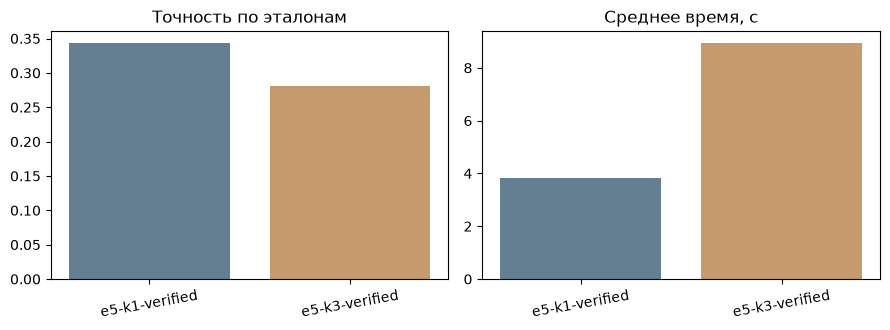

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
names = [item["name"] for item in summaries]
for axis, metric, title in zip(axes, ["accuracy", "mean_seconds"], ["Точность по эталонам", "Среднее время, с"]):
    axis.bar(names, [item["metrics"][metric] for item in summaries], color=["#647f91", "#c59a6c"])
    axis.set_title(title)
    axis.tick_params(axis="x", rotation=10)
fig.tight_layout()
fig.savefig(ROOT / "coursework/eval/results/comparison.png", dpi=140)
plt.show()

Второй проход той же маленькой модели не является независимым экспертом. Ошибки и отказы нужно читать в файлах результатов; сам факт ДА у проверяющего не доказывает истинность. Разбор примеров и ограничения — в README.